In [1]:
import glob
from datetime import datetime, timedelta, timezone
import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import cartopy
import cartopy.crs as ccrs
import numpy as np
import pandas as pd
import xarray as xr
from scipy.stats import genextreme as gev
import cmdline_provenance as cmdprov

from unseen import fileio
from unseen import array_handling
from unseen import process_utils
from unseen import eva
from unseen import stability
from unseen import independence
from unseen import bias_correction
from unseen import time_utils
from unseen import general_utils
#from unseen import moments
from unseen import similarity
from unseen import spatial_selection

In [63]:
model = 'CanESM5'
var = 'pr'
levels_dict = {}
levels_dict[var] = np.arange(0, 101, 10)
levels_dict['psl'] = np.arange(900, 1100, 3)
levels_dict['zg500'] = np.arange(5000, 6300, 50)
var_cmap = 'YlGnBu'
metric = 'Rx5day'
metric_long = 'Annual maximum 5-day rainfall total'
units = 'mm'
units_dict = {}
units_dict[var] = units
units_dict['psl'] = 'hPa'
units_dict['zg500'] = 'm'
baseline_period = ['1970-01-01', '2017-12-30'] 
correction_method = 'multiplicative'

region_name = 'CentralPakistan'
region_lat0 = -10 
region_lat1 = 60
region_lon0 = 40
region_lon1 = 160

map_proj = ccrs.PlateCarree(central_longitude=180)

box_name = 'Central Pakistan'
box_lat0 = 24
box_lat1 = 33
box_lon0 = 65
box_lon1 = 71

dist_min = 0
dist_max = 120

outdir = '/g/data/xv83/unseen-projects/outputs/wcrp-rx5day/data'
obs_file = f'{outdir}/rx5day_ERA5_1940-2025_annual_central-pakistan.nc'
model_file = f'{outdir}/rx5day_CanESM5-dcppA-hindcast_196101-201701_annual_central-pakistan.nc'

annual_infile_dict = {}
annual_infile_dict[var] = f'{outdir}/{var}-june-july_CanESM5-dcppA-hindcast_196101-201701_annual_north-america.nc'
annual_infile_dict['psl'] = f'{outdir}/psl-june-july_CanESM5-dcppA-hindcast_196101-201701_annual_north-america.nc'
annual_infile_dict['zg500'] = f'{outdir}/zg500-june-july_CanESM5-dcppA-hindcast_196101-201701_annual_north-america.nc'

code_url = 'https://github.com/AusClimateService/unseen-projects/tree/master/project-wcrp-rx5day'
history_log = cmdprov.new_log(code_url=code_url)

global_attrs = {
    'institution': 'CSIRO',
    'method': 'UNSEEN',
    'event': 'Pakistan Floods',
    'project': 'WCRP Common Event Attribution and Assessment',
    'contact': 'damien.irving@csiro.au',
    'source': model,
    'experiment': 'dcppA-hindcast',
    'references': 'Decadal Climate Prediction Project (DCPP): https://doi.org/10.5194/gmd-9-3751-2016. UNSEEN methodology: https://doi.org/10.1002/met.70118',
    'creation_date': datetime.now(timezone.utc).strftime('%Y-%m-%dT%H:%M:%SZ'),
    'history': history_log,
}
    

In [3]:
#baseline_start = baseline_period[0][0:4]
#baseline_end = baseline_period[1][0:4]

In [4]:
def get_encoding(ds, skip_vars=[]):
    """Output file encoding."""

    encoding = {}
    ds_vars = list(ds.coords) + list(ds.keys())
    for ds_var in ds_vars:
        if ds_var not in skip_vars:
            encoding[ds_var] = {'_FillValue': None}

    return encoding

In [5]:
def likelihood(data, event):
    """Calculate event likelihood"""

    shape, loc, scale = eva.fit_gev(data)
    probability = gev.sf(event, shape, loc=loc, scale=scale)
    return_period = 1. / probability
    percentile = (1 - probability) * 100
    print(f'{return_period:.0f} year return period')
    print(f'{percentile:.2f}% percentile')

    return shape, loc, scale

## Read observations

In [6]:
obs_ds = fileio.open_dataset(obs_file)
obs_ds = obs_ds.dropna("time")

In [7]:
obs_2022_event = obs_ds[var].sel(time=slice('2022-01-01', '2022-12-31')).values[0]
print(obs_2022_event)

82.96943293191512


In [8]:
#obs_ds_baseline = time_utils.select_time_period(obs_ds, baseline_period)
obs_ds_baseline = obs_ds.copy()

## Read (and test) model data

In [9]:
model_ds = fileio.open_dataset(model_file)

In [10]:
model_ds = model_ds.compute()
model_ds

<xarray.Dataset> Size: 552kB
Dimensions:     (init_date: 57, ensemble: 20, lead_time: 10)
Coordinates:
    event_time  (init_date, ensemble, lead_time) <U10 456kB '1961-12-26' ... ...
  * ensemble    (ensemble) int64 160B 0 1 2 3 4 5 6 7 ... 13 14 15 16 17 18 19
  * lead_time   (lead_time) int64 80B 0 1 2 3 4 5 6 7 8 9
  * init_date   (init_date) object 456B 1961-01-01 00:00:00 ... 2017-01-01 00...
    time        (lead_time, init_date) object 5kB 1961-01-01 00:00:00 ... 202...
Data variables:
    pr          (init_date, ensemble, lead_time) float64 91kB 7.163 ... 8.02
Attributes: (12/53)
    CCCma_model_hash:            Unknown
    CCCma_parent_runid:          d2a-asm-e01
    CCCma_pycmor_hash:           13db8596c37129e414cad7ae31f2927ca8f5dd39
    CCCma_runid:                 d2a196101e01
    Conventions:                 CF-1.7 CMIP-6.2
    YMDH_branch_time_in_child:   1961:01:01:00
    ...                          ...
    tracking_id:                 hdl:21.14100/f220e01c-1214-4625-be6a-c0475c2...
    variable_id:                 pr
    variant_label:               r1i1p2f1
    version:                     v20190429
    license:                     CMIP6 model data produced by The Government ...
    cmor_version:                3.4.0

#### Stability and stationarity

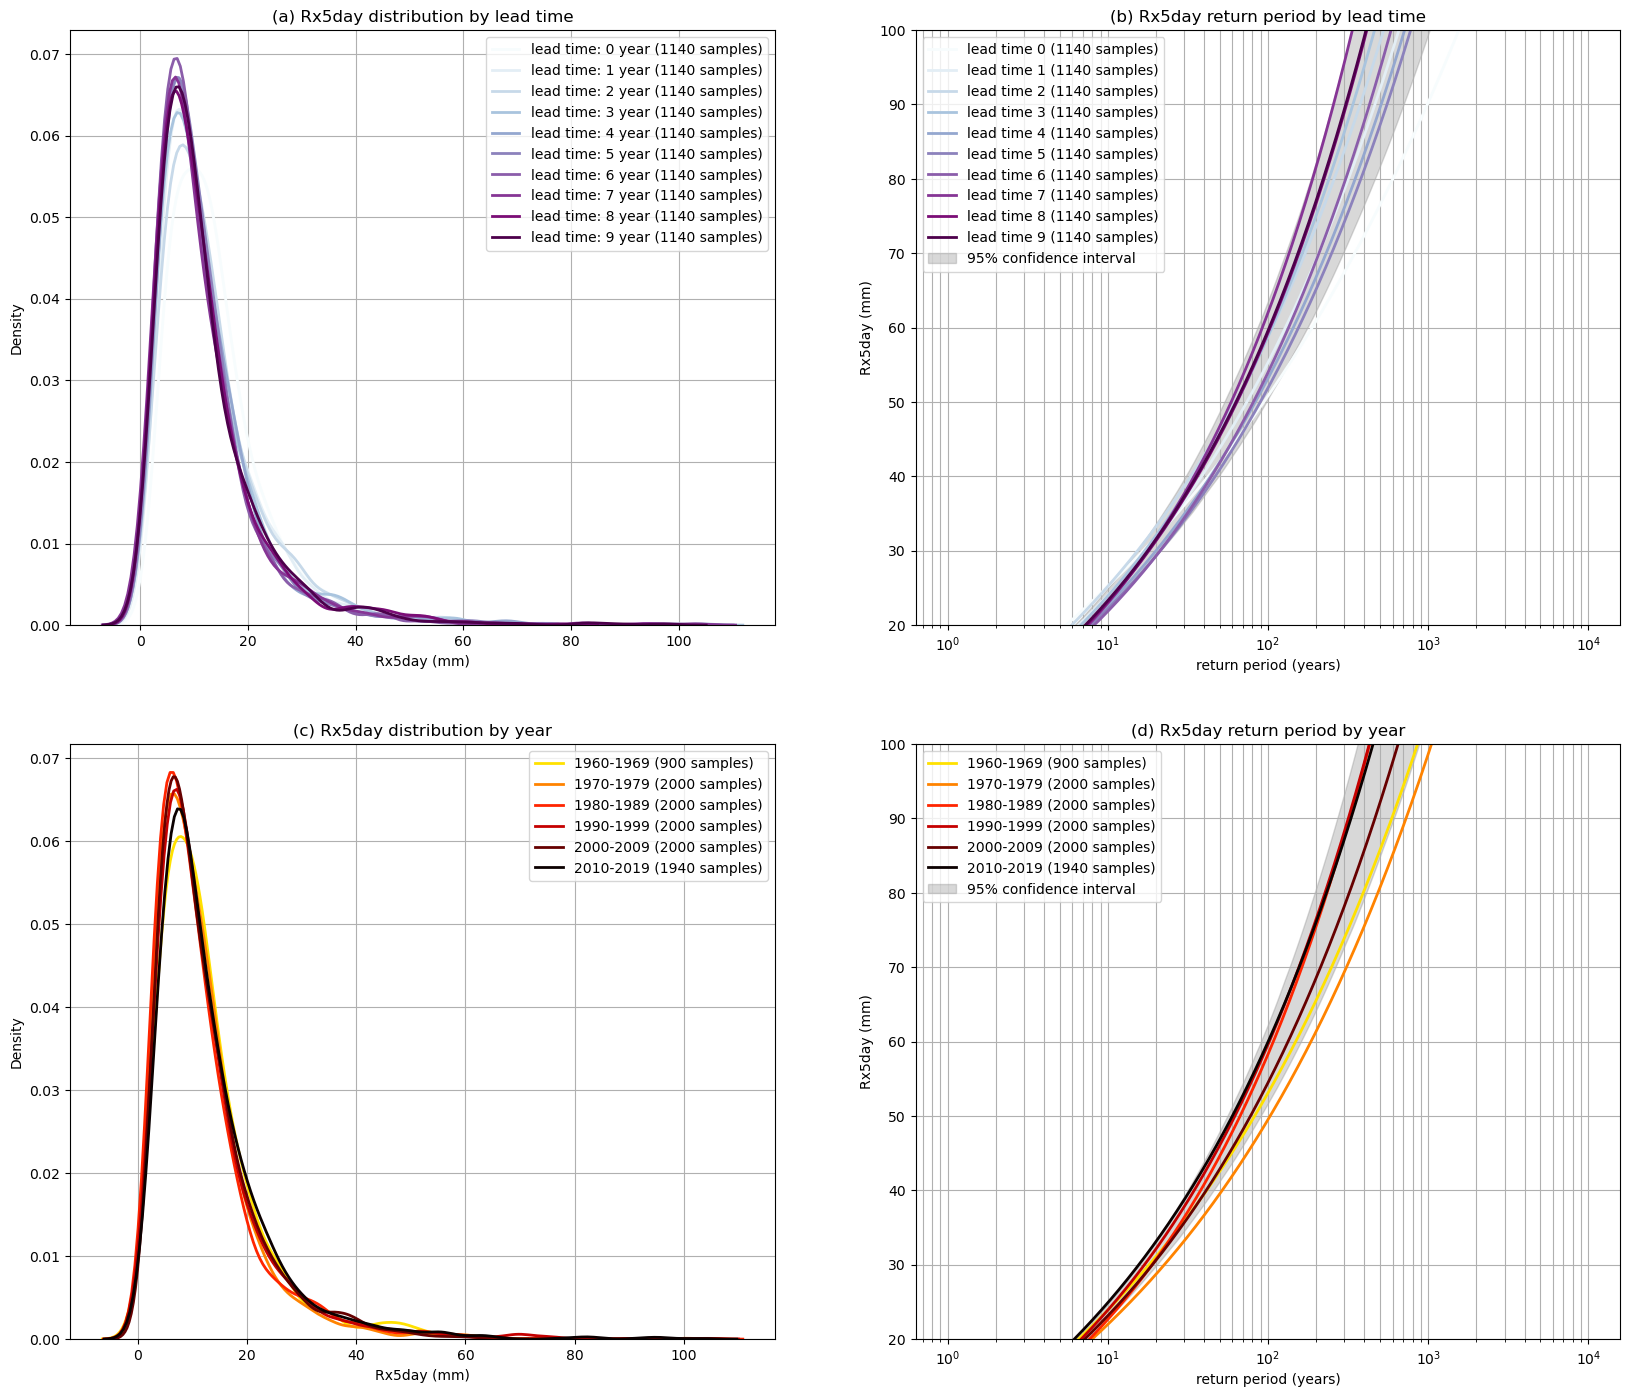

In [12]:
stability.create_plot(
    model_ds[var],
    metric,
    [1960, 1970, 1980, 1990, 2000, 2010],
    uncertainty=True,
    return_method='gev',
    units=f'{metric} ({units})',
    ylim=(dist_min, dist_max),
)

#### Independence

In [13]:
independence_ds = independence.run_tests(model_ds[var])

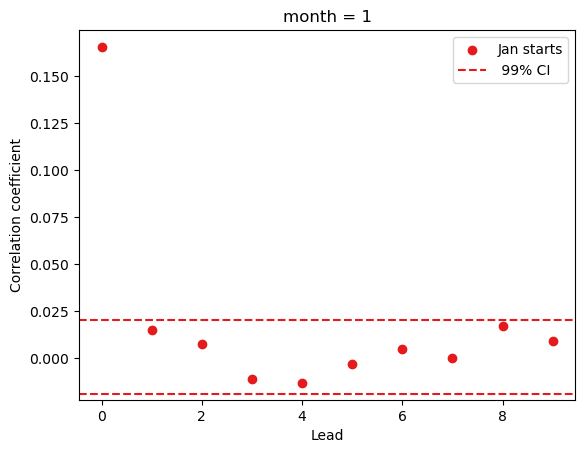

In [14]:
independence.point_plot(
    independence_ds,
    confidence_interval=0.99,
)

In [15]:
min_lead = 1

Drop lead times that aren't independent...

In [16]:
model_da_indep = model_ds[var].where(model_ds['lead_time'] >= min_lead)
model_da_indep = model_da_indep.dropna('lead_time')

In [17]:
model_da_indep_stacked = model_da_indep.stack({'sample': ['ensemble', 'init_date', 'lead_time']})

In [18]:
model_da_indep_baseline = time_utils.select_time_period(model_da_indep, baseline_period)
model_da_indep_baseline_stacked = model_da_indep_baseline.stack({'sample': ['ensemble', 'init_date', 'lead_time']})

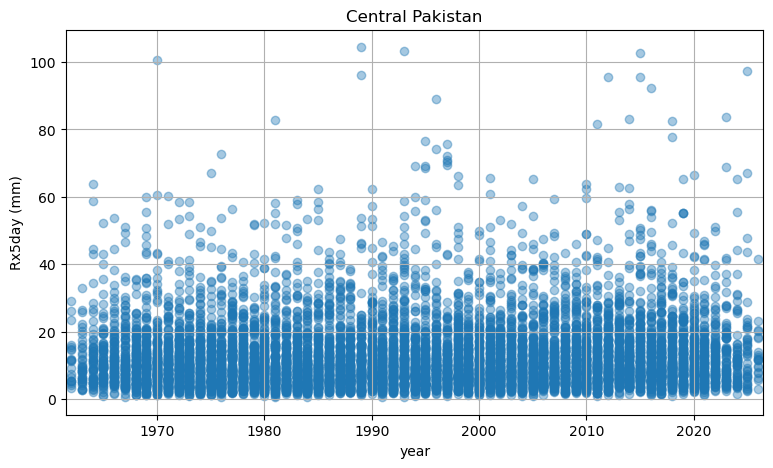

In [19]:
fig, ax = plt.subplots(figsize=[9, 5])
years = model_da_indep_stacked['time'].dt.year.values
unique_years = np.unique(model_da_indep_stacked.time.dt.year.values)

plt.scatter(
    years,
    model_da_indep_stacked.values,
    marker='o',
    color='tab:blue',
    alpha=0.4,
    label='raw data'
)
plt.xlim(unique_years[0] - 0.5, unique_years[-1] + 0.5)
plt.title(box_name)
plt.ylabel(f'{metric} ({units})')
plt.xlabel('year')
#plt.legend()
plt.grid()
plt.show()

#### Bias correction

In [20]:
bias = bias_correction.get_bias(
    model_da_indep,
    obs_ds[var],
    correction_method,
    time_rounding='A',
    time_period=baseline_period
)
print(bias)

<xarray.DataArray 'pr' (month: 1)> Size: 8B
dask.array<divide, shape=(1,), dtype=float64, chunksize=(1,), chunktype=numpy.ndarray>
Coordinates:
  * month    (month) int64 8B 1
Attributes:
    units:                   mm d-1
    standard_name:           lwe_precipitation_rate
    climatological_period:   ['1970-01-01', '2017-12-30']
    bias_correction_method:  multiplicative
    bias_correction_period:  1970-01-01-2017-12-30


In [21]:
bias_value = bias.values[0]
print(bias_value)

0.313241541417035


In [22]:
model_da_bc = bias_correction.remove_bias(model_da_indep, bias, correction_method)

In [23]:
model_da_bc = model_da_bc.compute()

In [24]:
model_da_bc_stacked = model_da_bc.stack({'sample': ['ensemble', 'init_date', 'lead_time']})

In [25]:
model_da_bc_baseline = time_utils.select_time_period(model_da_bc, baseline_period)
model_da_bc_baseline_stacked = model_da_bc_baseline.stack({'sample': ['ensemble', 'init_date', 'lead_time']})

#### Similarity testing

In [26]:
def plot_dist(time_period='full'):
    """Plot distribution."""

    assert time_period in ['full', 'baseline']

    fig, ax = plt.subplots(figsize=[8, 5])
    xvals = np.arange(dist_min, dist_max, 0.1)

    if time_period == 'baseline':
        title = f'{box_name} - comparison period ({baseline_start}-{baseline_end})'
        model_da_indep_baseline.plot.hist(bins=20, density=True, alpha=0.7, facecolor='tab:blue')
        model_raw_shape, model_raw_loc, model_raw_scale = eva.fit_gev(model_da_indep_baseline_stacked.values, use_basinhopping=True)
        model_da_bc_baseline.plot.hist(bins=50, density=True, alpha=0.7, facecolor='tab:orange')
        model_bc_shape, model_bc_loc, model_bc_scale = eva.fit_gev(model_da_bc_baseline_stacked.values, use_basinhopping=True)
        obs_ds_baseline[var].plot.hist(ax=ax, bins=50, density=True, facecolor='tab:gray', alpha=0.7)
        obs_shape, obs_loc, obs_scale = eva.fit_gev(obs_ds_baseline[var].values, use_basinhopping=True)
    else:
        title = f'{box_name} - full timeseries'
        model_da_indep.plot.hist(bins=20, density=True, alpha=0.7, facecolor='tab:blue')
        model_raw_shape, model_raw_loc, model_raw_scale = eva.fit_gev(model_da_indep_stacked.values, use_basinhopping=True)
        model_da_bc.plot.hist(bins=50, density=True, alpha=0.7, facecolor='tab:orange')
        model_bc_shape, model_bc_loc, model_bc_scale = eva.fit_gev(model_da_bc_stacked.values, use_basinhopping=True)
        obs_ds[var].plot.hist(ax=ax, bins=50, density=True, facecolor='tab:gray', alpha=0.7)
        obs_shape, obs_loc, obs_scale = eva.fit_gev(obs_ds[var].values, use_basinhopping=True)
    
    model_raw_pdf = gev.pdf(xvals, model_raw_shape, model_raw_loc, model_raw_scale)
    plt.plot(xvals, model_raw_pdf, color='tab:blue', linewidth=4.0, label='model')
    
    model_bc_pdf = gev.pdf(xvals, model_bc_shape, model_bc_loc, model_bc_scale)
    plt.plot(xvals, model_bc_pdf, color='tab:orange', linewidth=4.0, label='model (corrected)')
    
    obs_pdf = gev.pdf(xvals, obs_shape, obs_loc, obs_scale)
    plt.plot(xvals, obs_pdf, color='tab:gray', linewidth=4.0, label='ERA5')
    
    plt.xlabel(f'{metric} ({units})')
    plt.ylabel('probability')
    plt.title(title)
    plt.xlim(dist_min, dist_max)
    plt.legend()
    plt.grid()
    plt.show()

In [28]:
#plot_dist(time_period='baseline')

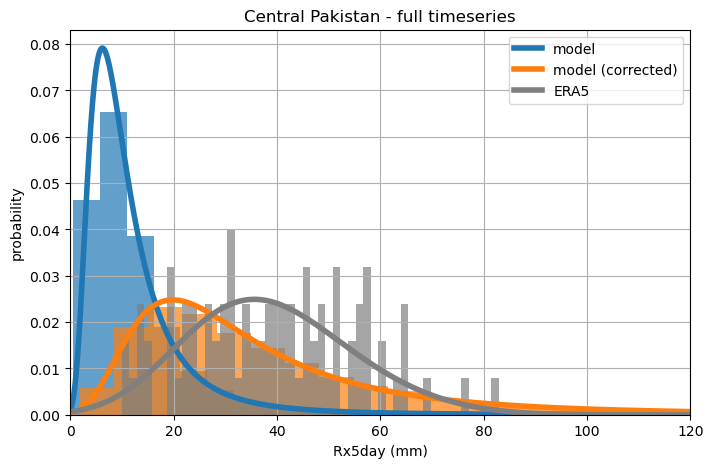

In [31]:
plot_dist(time_period='full')

In [32]:
#moments.create_plot(
#    model_da_indep_baseline,
#    obs_ds_baseline[var],
#    da_bc_fcst=model_da_bc_baseline,
#)

In [33]:
similarity_ds_indep = similarity.similarity_tests(model_da_indep_baseline, obs_ds_baseline[var])
print('KS score:', similarity_ds_indep['ks_statistic'].values)
print('KS p-value:', similarity_ds_indep['ks_pval'].values)
print('AD score:', similarity_ds_indep['ad_statistic'].values)
print('AD p-value:', similarity_ds_indep['ad_pval'].values)

KS score: 0.7477175
KS p-value: 0.0
AD score: 197.56447
AD p-value: 0.001


In [34]:
similarity_ds_bc = similarity.similarity_tests(model_da_bc_baseline, obs_ds_baseline[var])
print('KS score:', similarity_ds_bc['ks_statistic'].values)
print('KS p-value:', similarity_ds_bc['ks_pval'].values)
print('AD score:', similarity_ds_bc['ad_statistic'].values)
print('AD p-value:', similarity_ds_bc['ad_pval'].values)

KS score: 0.20600775
KS p-value: 0.0012013522
AD score: 7.3763647
AD p-value: 0.001


p > 0.05 means that the null hypothesis (that the two samples are from the same population) cannot be rejected.

In [42]:
if similarity_ds_indep['ks_pval'].values > 0.05:
    model_da_samples_stacked = model_da_indep_stacked
    step_bias = f'No bias correction was applied to the {metric} values.'
elif similarity_ds_bc['ks_pval'].values > 0.05:
    model_da_samples_stacked = model_da_bc_stacked
    step_bias = f'Applied bias correction (additve mean scaling) to the {metric} values.'
else:
    #raise Exception('Data fails similarity test before and after bias correction')
    model_da_samples_stacked = model_da_indep_stacked
    step_bias = f'No bias correction was applied to the {metric} values.'
    print('Data fails similarity test before and after bias correction')

Data fails similarity test before and after bias correction


In [43]:
print(step_bias)

No bias correction was applied to the Rx5day values.


#### Process assessment

In [44]:
def ensemble_to_run(model_name, ensnum):
    """Map ensemble number to DCPP model run"""

    norcpm_dict = {
        1: 'r1i1p1f1',
        2: 'r1i2p1f1',
        3: 'r2i1p1f1',
        4: 'r2i2p1f1',
        5: 'r3i1p1f1',
        6: 'r3i2p1f1',
        7: 'r4i1p1f1',
        8: 'r4i2p1f1',
        9: 'r5i1p1f1',
        10: 'r5i2p1f1',
        11: 'r6i1p1f1',
        12: 'r6i2p1f1',
        13: 'r7i1p1f1',
        14: 'r7i2p1f1',
        15: 'r8i1p1f1',
        16: 'r8i2p1f1',
        17: 'r9i1p1f1',
        18: 'r9i2p1f1',
        19: 'r10i1p1f1',
        20: 'r10i2p1f1',
    }

    ecearth_dict = {
        1: 'r1i1p1f1',
        2: 'r2i1p1f1',
        3: 'r3i1p1f1',
        4: 'r4i1p1f1',
        5: 'r5i1p1f1',
        6: 'r6i1p1f1',
        7: 'r6i2p1f1',
        8: 'r7i1p1f1',
        9: 'r7i2p1f1',
        10: 'r8i1p1f1',
        11: 'r8i2p1f1',
        12: 'r9i1p1f1',
        13: 'r9i2p1f1',
        14: 'r10i1p1f1',
        15: 'r10i2p1f1',
    }

    if model_name == 'EC-Earth3':
        run = ecearth_dict[ensnum]
    elif model_name == 'NorCPM1':
        run = norcpm_dict[ensnum]
    else:
        ensemble_to_run = { 
            'BCC-CSM2-MR': f'r{ensnum}i1p1f1',
            'CanESM5': f'r{ensnum}i1p2f1',
            'CMCC-CM2-SR5': f'r{ensnum}i1p1f1',
            'HadGEM3-GC31-MM': f'r{ensnum}i1p1f2',
            'IPSL-CM6A-LR': f'r{ensnum}i1p1f1',
            'MIROC6': f'r{ensnum}i1p1f1',
            'MPI-ESM1-2-HR': f'r{ensnum}i1p1f1',
            'MRI-ESM2-0': f'r{ensnum}i1p1f1',
        }
        run = ensemble_to_run[model_name]

    return run
    

def find_dcpp_data(event_df_row, model_name):
    """Find DCPP data for one row of a dataframe of events."""

    init_adjustment = {
        'BCC-CSM2-MR': 0,
        'CanESM5': -1,
        'CMCC-CM2-SR5': -1,
        'EC-Earth3': -1,
        'IPSL-CM6A-LR': -1,
        'MIROC6': -1,
        'MPI-ESM1-2-HR': -1,
        'MRI-ESM2-0': -1,
        'NorCPM1': -1,
    }

    assert model_name in init_adjustment
    
    init_date = int(event_df_row['init_date'].strftime('%Y')) + init_adjustment[model_name]
    ensemble = int(event_df_row['ensemble']) + 1
    run = ensemble_to_run(model_name, ensemble)
    event_date = event_df_row['event_time']
    event_value = round(float(event_df_row[var]), 1)
    event_summary = f'{metric} of {event_value} on {event_date}: initialisation year {init_date}, ensemble member {run}'
    print(event_summary)
    var_files = glob.glob(f'/g/data/oi10/replicas/CMIP6/DCPP/*/{model_name}/dcppA-hindcast/s{init_date}-{run}/day/{var}/*/*/*.nc')
    assert var_files
    psl_files = glob.glob(f'/g/data/oi10/replicas/CMIP6/DCPP/*/{model_name}/dcppA-hindcast/s{init_date}-{run}/day/psl/*/*/*.nc')
    zg500_files = glob.glob(f'/g/data/oi10/replicas/CMIP6/DCPP/*/{model_name}/dcppA-hindcast/s{init_date}-{run}/AERday/zg500/*/*/*.nc')

    return var_files, psl_files, zg500_files, event_date, event_value, event_summary

In [51]:
def event_check(da, event_value):
    """Check the event value"""

    da_box = da.sel(lat=slice(box_lat0, box_lat1), lon=slice(box_lon0, box_lon1))
    da_box_mean = spatial_selection.aggregate(da_box, 'weighted_mean')
    
    np.testing.assert_approx_equal(float(da_box_mean), event_value, significant=1)
    # np.testing.assert_approx_equal(float(da_box_mean) - bias_value, event_value, significant=1)
    

def get_start_date(event_date):
    """Get start date."""

    event_datetime = datetime.strptime(event_date, "%Y-%m-%d")
    start_datetime = event_datetime - timedelta(days=4)
    start_date = start_datetime.strftime("%Y-%m-%d")

    return start_date


def get_event_data(event_df_row, model_name):
    """Plot an event"""

    infiles_var, infiles_psl, infiles_zg500, event_date, event_value, event_summary = find_dcpp_data(event_df_row, model_name)
    dcpp_config = '/home/599/dbi599/unseen-projects/dataset_config/dataset_dcpp.yml'

    start_date = get_start_date(event_date)

    ds_var = fileio.open_dataset(infiles_var, metadata_file=dcpp_config)
    ds_var = ds_var.sel(
        time=slice(start_date, event_date),
        lat=slice(region_lat0 - 5, region_lat1 + 5),
        lon=slice(region_lon0 - 5, region_lon1 + 5),
    )
    da_var = general_utils.convert_units(ds_var[var], units)
    da_var = da_var.sum('time')
    event_check(da_var, event_value)

    if infiles_psl:
        ds_psl = fileio.open_dataset(infiles_psl, metadata_file=dcpp_config)
        ds_psl = ds_psl.sel(
            time=slice(start_date, event_date),
            lat=slice(region_lat0 - 5, region_lat1 + 5),
            lon=slice(region_lon0 - 5, region_lon1 + 5),
        )
        da_psl = general_utils.convert_units(ds_psl['psl'], 'hPa')
        da_psl = da_psl.mean('time')
    else:
        da_psl = None
    
    if infiles_zg500:
        ds_zg500 = fileio.open_dataset(infiles_zg500, metadata_file=dcpp_config)
        ds_zg500 = ds_zg500.sel(
            time=slice(start_date, event_date),
            lat=slice(region_lat0 - 5, region_lat1 + 5),
            lon=slice(region_lon0 - 5, region_lon1 + 5),
        )
        da_zg500 = ds_zg500['zg500']
        da_zg500 = da_zg500.mean('time')
    else:
        da_zg500 = None

    return da_var, da_psl, da_zg500

In [52]:
def plot_event(da_var, da_contour, contour_var):
    """Plot event."""

    assert contour_var in ['psl', 'zg500']
    
    fig = plt.figure(figsize=[15, 5])
    ax = fig.add_subplot(111, projection=map_proj)
    
    da_var.plot(
        ax=ax,
        transform=ccrs.PlateCarree(),
        cmap=var_cmap,
        levels=levels_dict[var],
        extend='both',
    #    cbar_kwargs={"label": label},
    )
    if type(da_contour) != type(None):
        lines = da_contour.plot.contour(
            ax=ax,
            transform=ccrs.PlateCarree(),
            levels=levels_dict[contour_var],
            colors=["0.3"]
        )
        ax.clabel(lines, colors=["0.3"], manual=False, inline=True)
    
    ax.plot(
        [box_lon0, box_lon0, box_lon1, box_lon1, box_lon0],
        [box_lat1, box_lat0, box_lat0, box_lat1, box_lat1],
        transform=ccrs.PlateCarree(),
        color='green',
    )   
    ax.coastlines()
    #ax.set_extent([180, 300, 30, 70], crs=ccrs.PlateCarree(central_longitude=0))
    ax.add_feature(cartopy.feature.BORDERS)
    ax.gridlines(linestyle="--", draw_labels=True)
    
    plt.show()

In [53]:
model_da_samples_stacked_df = model_da_samples_stacked.to_dataframe()
nsamples = len(model_da_samples_stacked_df)
model_da_samples_stacked_df.index = range(1, nsamples + 1)
model_da_samples_stacked_df_sorted = model_da_samples_stacked_df.sort_values(by=[var], ascending=False)
model_da_samples_stacked_df_sorted.head(n=10)

,event_time,time,ensemble,init_date,lead_time,pr
3819,1989-10-30,1989-01-01 00:00:00,7,1986-01-01 00:00:00,3,104.395034
1779,1993-12-16,1993-01-01 00:00:00,3,1987-01-01 00:00:00,6,103.199946
8638,2015-12-21,2015-01-01 00:00:00,16,2008-01-01 00:00:00,7,102.683097
3143,1970-10-25,1970-01-01 00:00:00,6,1968-01-01 00:00:00,2,100.499161
7173,2025-11-30,2025-01-01 00:00:00,13,2016-01-01 00:00:00,9,97.477979
3787,1989-12-11,1989-01-01 00:00:00,7,1982-01-01 00:00:00,7,96.008687
7112,2012-10-19,2012-01-01 00:00:00,13,2010-01-01 00:00:00,2,95.662375
4566,2015-02-01,2015-01-01 00:00:00,8,2012-01-01 00:00:00,3,95.429216
2491,2016-12-21,2016-01-01 00:00:00,4,2009-01-01 00:00:00,7,92.398421
7425,1996-12-27,1996-01-01 00:00:00,14,1987-01-01 00:00:00,9,89.060424


In [54]:
nsamples = len(model_da_samples_stacked_df)
print(f'Total number of samples: {nsamples}')

Total number of samples: 10260


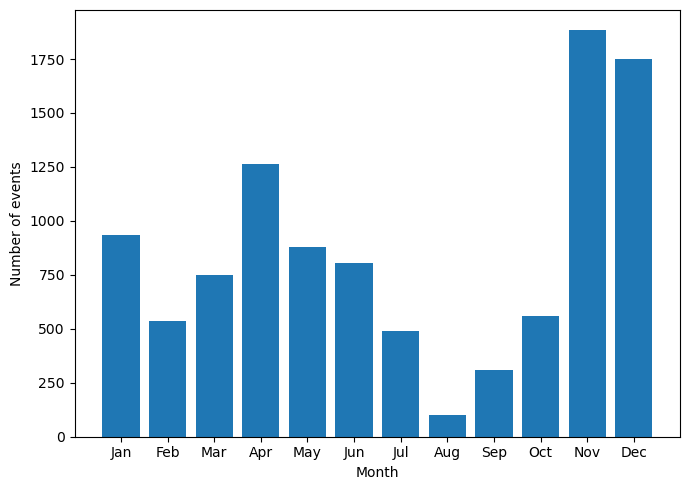

In [55]:
process_utils.plot_event_seasonality(model_da_samples_stacked, core_dim='sample')

Rx5day of 104.4 on 1989-10-30: initialisation year 1985, ensemble member r8i1p2f1


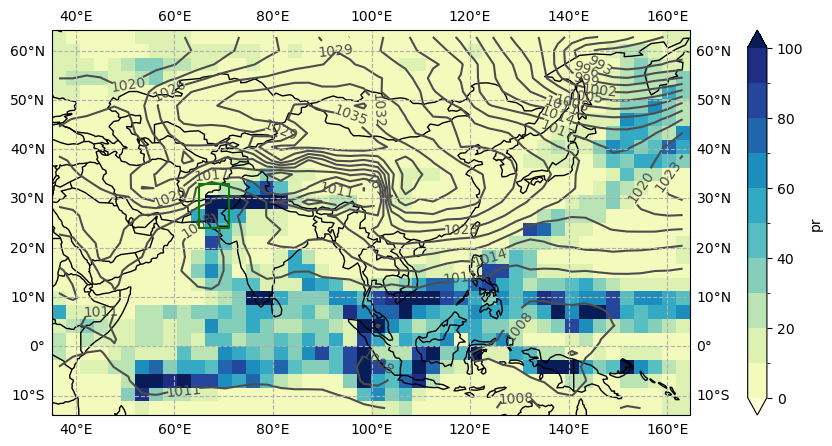

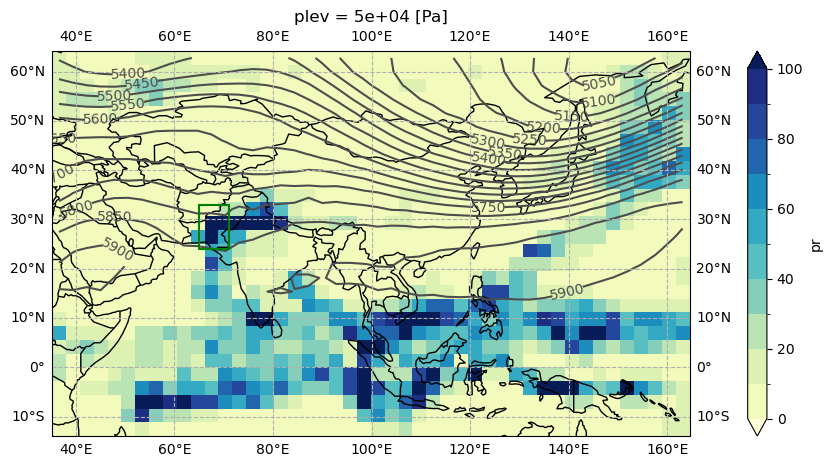

Rx5day of 103.2 on 1993-12-16: initialisation year 1986, ensemble member r4i1p2f1


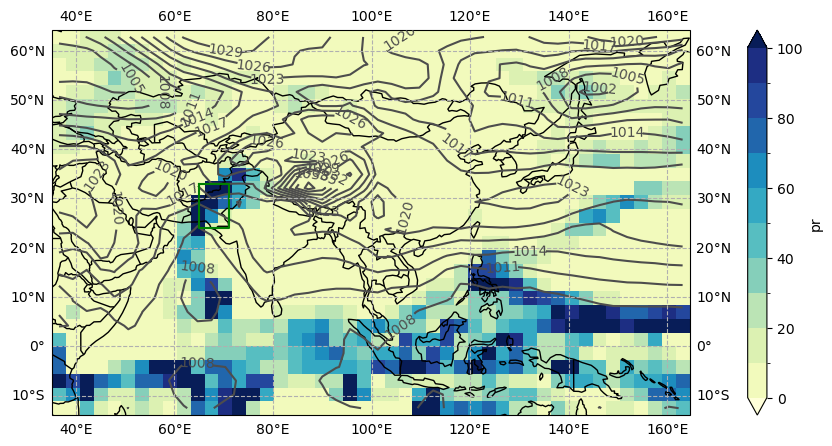

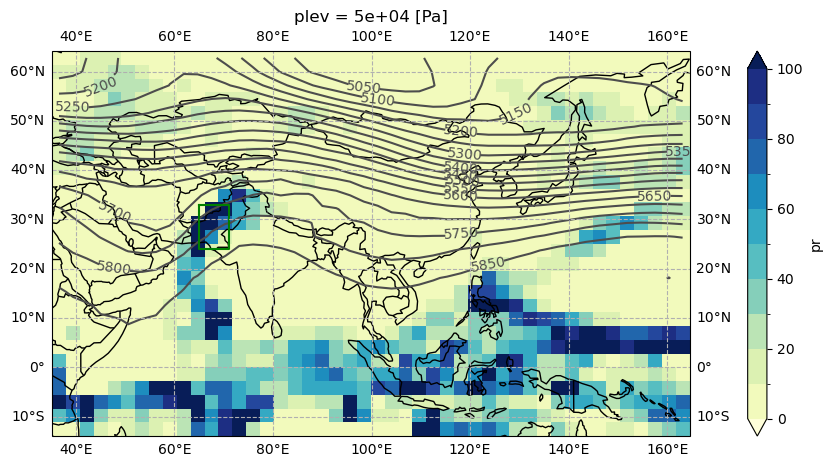

Rx5day of 102.7 on 2015-12-21: initialisation year 2007, ensemble member r17i1p2f1


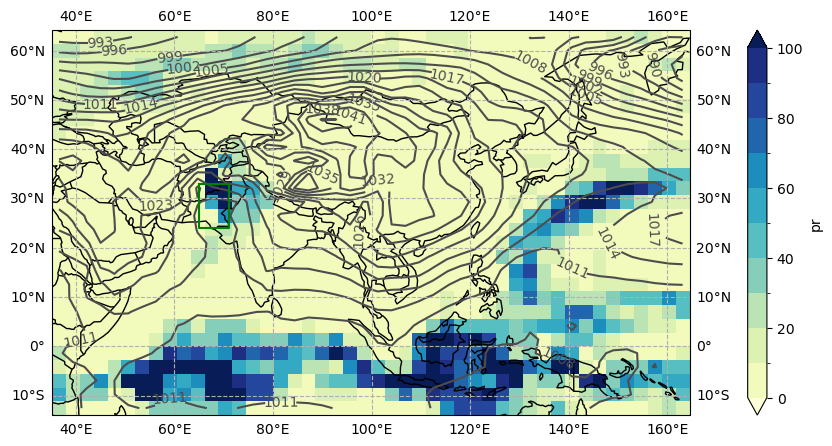

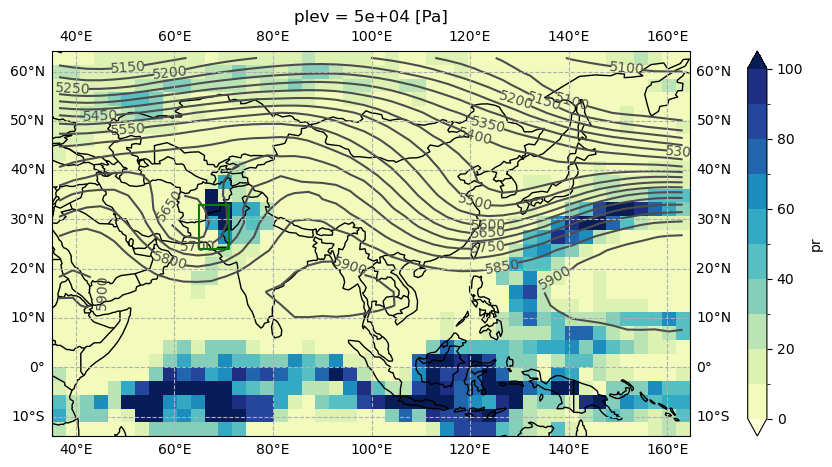

Rx5day of 100.5 on 1970-10-25: initialisation year 1967, ensemble member r7i1p2f1


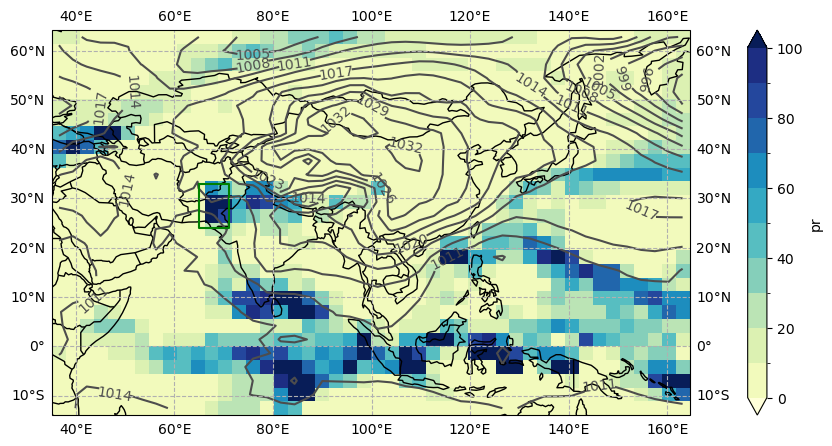

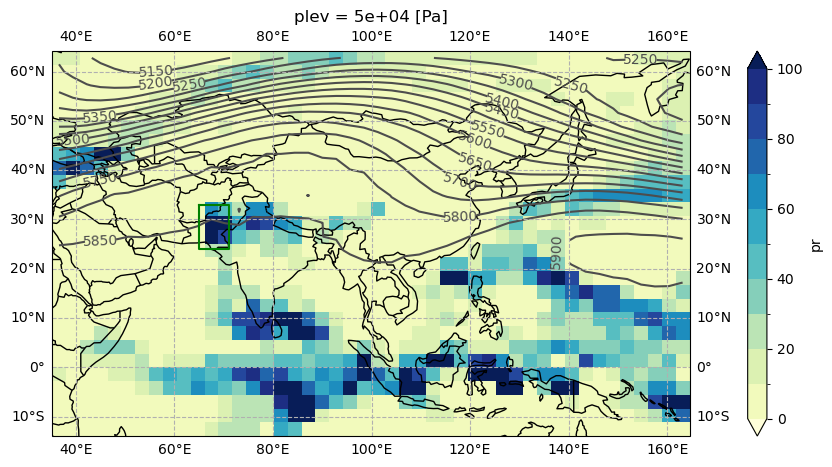

Rx5day of 97.5 on 2025-11-30: initialisation year 2015, ensemble member r14i1p2f1


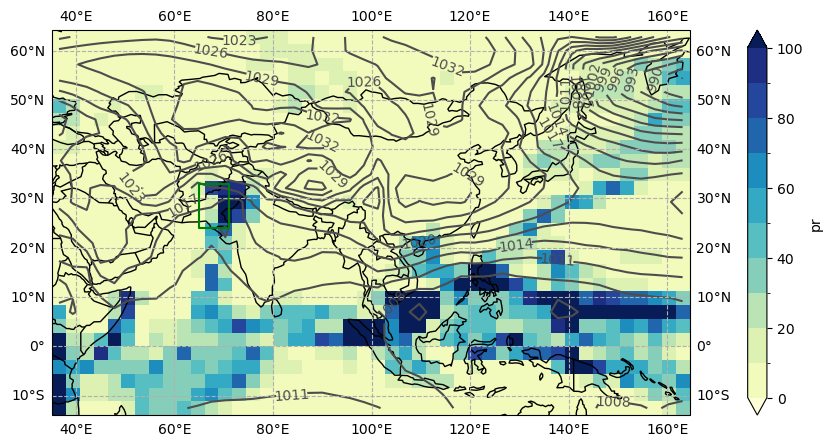

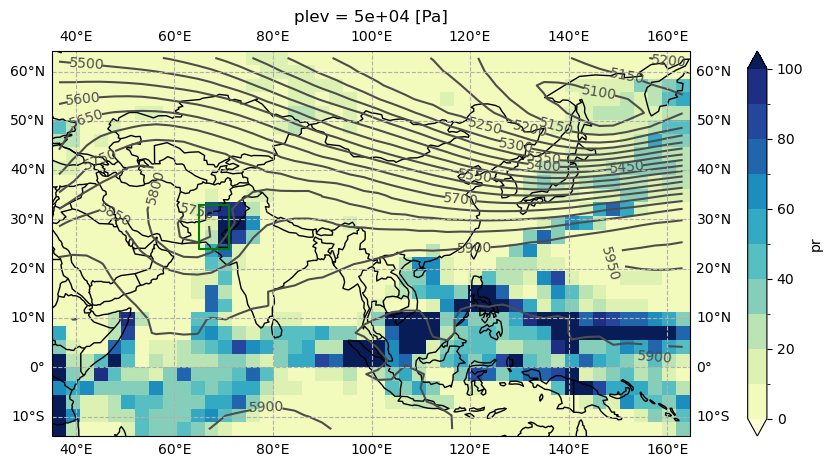

Rx5day of 96.0 on 1989-12-11: initialisation year 1981, ensemble member r8i1p2f1


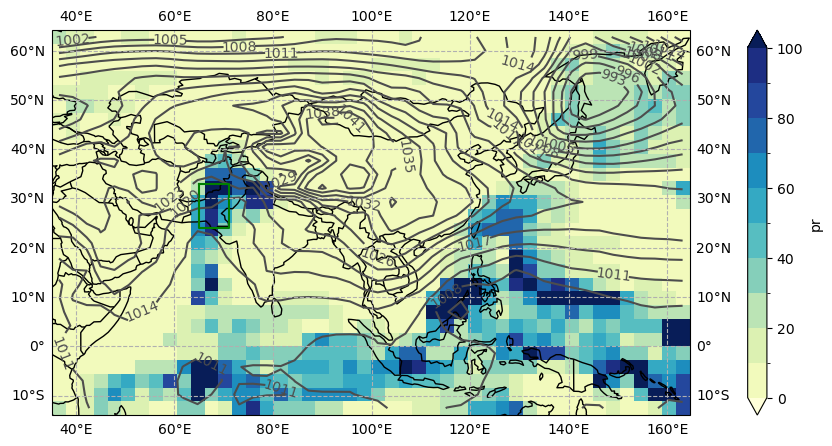

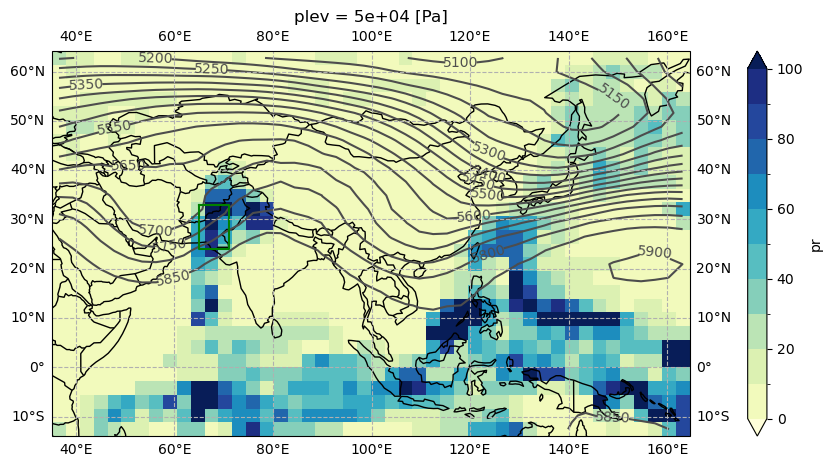

Rx5day of 95.7 on 2012-10-19: initialisation year 2009, ensemble member r14i1p2f1


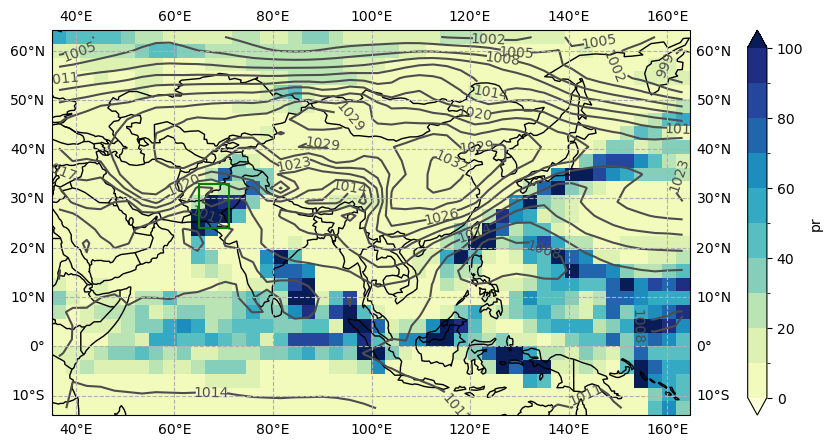

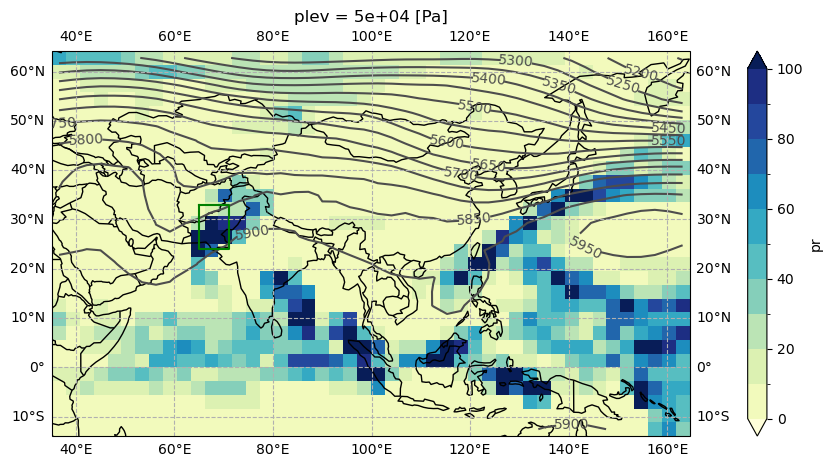

Rx5day of 95.4 on 2015-02-01: initialisation year 2011, ensemble member r9i1p2f1


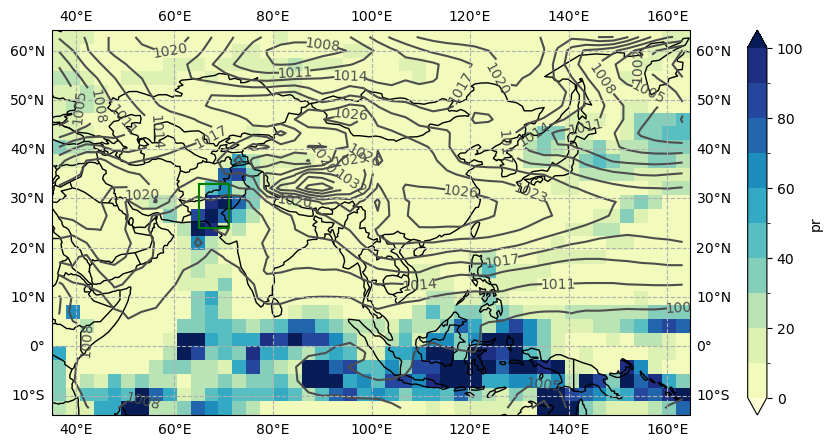

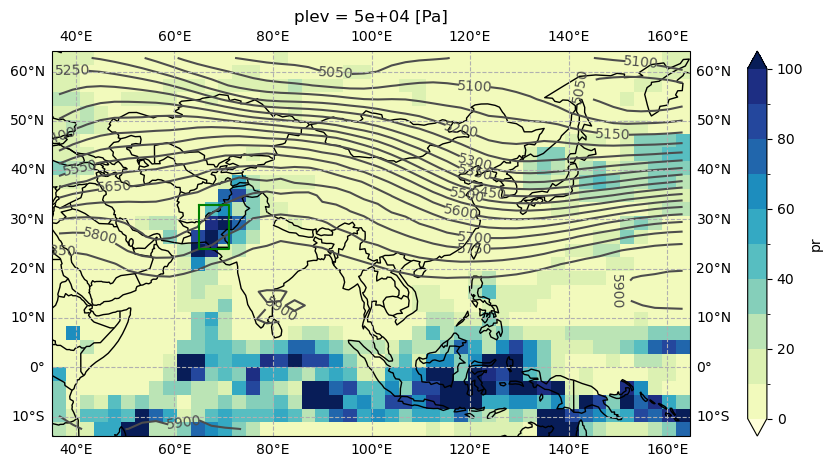

Rx5day of 92.4 on 2016-12-21: initialisation year 2008, ensemble member r5i1p2f1


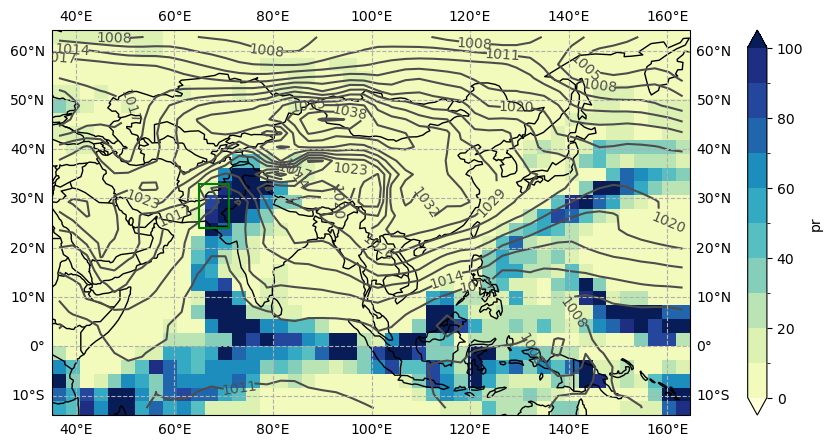

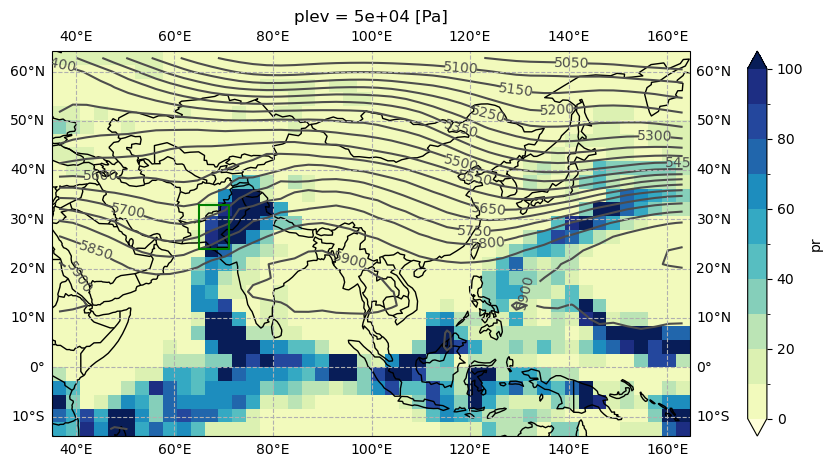

Rx5day of 89.1 on 1996-12-27: initialisation year 1986, ensemble member r15i1p2f1


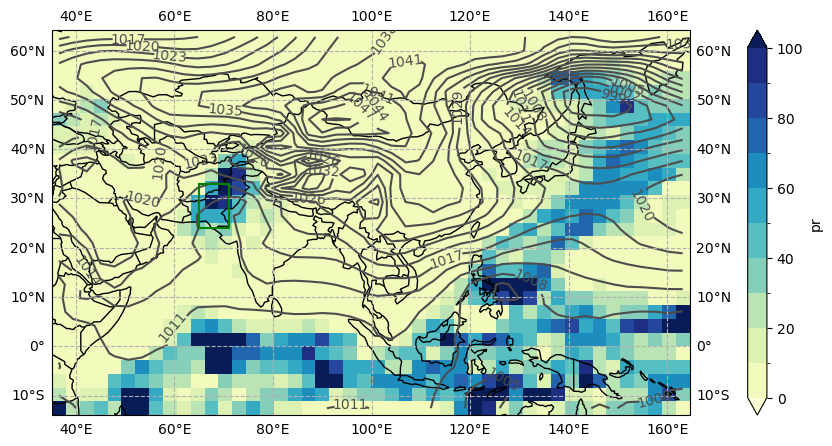

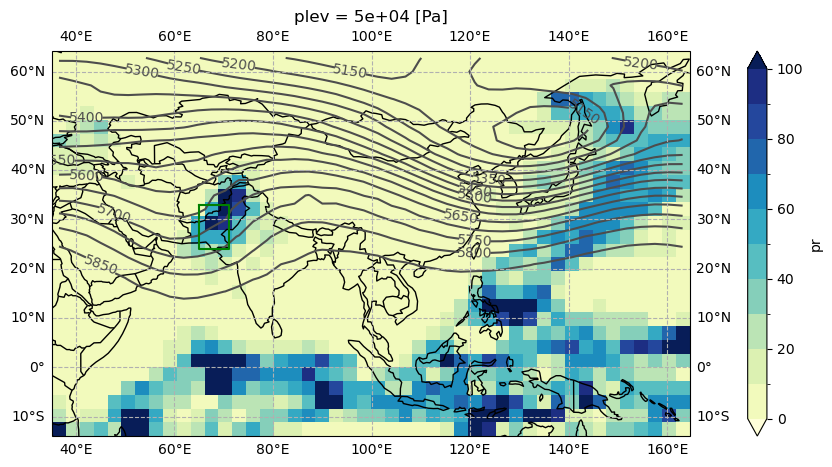

In [64]:
da_var_dict = {}
da_psl_dict = {}
da_zg500_dict = {}
for rank in range(10):
    number = model_da_samples_stacked_df_sorted.iloc[rank].name
    da_var_dict[number], da_psl_dict[number], da_zg500_dict[number] = get_event_data(
        model_da_samples_stacked_df_sorted.iloc[rank], model
    )
    plot_event(da_var_dict[number], da_psl_dict[number], 'psl')
    plot_event(da_var_dict[number], da_zg500_dict[number], 'zg500')

## Results

#### Non-stationary GEV

In [57]:
daparams = eva.fit_gev(
    model_da_samples_stacked,
    core_dim="sample",
    stationary=True,
    use_basinhopping=True,
)

In [58]:
for param, value in zip(daparams.dparams.values, daparams.values):
    print(param, value)

c -0.31074970531730056
location 7.4763533022082
scale 4.857338090810398


In [59]:
return_period = float(eva.get_return_period(obs_2022_event, daparams).values)

In [61]:
# parametric uncertainty estimate
n_bootstraps = 1000
shape, loc, scale = eva.unpack_gev_params(daparams)
sample_size = len(model_da_samples_stacked)
boot_samples = []
for i in range(n_bootstraps):
    boot_data = gev.rvs(float(shape), loc=float(loc), scale=float(scale), size=sample_size)
    boot_gev_params = eva.fit_gev(boot_data)
    boot_return_period = eva.get_return_period(obs_2022_event, boot_gev_params)
    boot_samples.append(boot_return_period)
ci05 = np.percentile(boot_samples, 5)
ci16 = np.percentile(boot_samples, 16)
ci84 = np.percentile(boot_samples, 84)
ci95 = np.percentile(boot_samples, 95)

In [62]:
print(f'The return period of a {obs_2022_event:.2f} {units} event is {return_period:.0f} years.')
print(f'The 5-95% confidence interval is {ci05:.0f} to {ci95:.0f} years.')
print(f'The 16-84% confidence interval is {ci16:.0f} to {ci84:.0f} years.')

The return period of a 82.97 mm event is 291 years.
The 5-95% confidence interval is 253 to 382 years.
The 16-84% confidence interval is 267 to 326 years.


## Supporting data

In [89]:
ecmwf_attrs = {}
ecmwf_attrs['pr'] = {
    'name': 'tp',
    'units': 'mm',
    'long_name': 'Total accumulated 5-day precipitation',
}
ecmwf_attrs['psl'] = {
    'name': 'msl',
    'units': 'Pa',
    'long_name': 'Mean sea level pressure',
}
ecmwf_attrs['zg500'] = {
    'name': 'gh500',
    'units': 'm',
    'long_name': 'Geopotential height at 500 hPa',
}

### Tier 2 data

In [ ]:
numbers = model_da_samples_stacked_df.index.values
da1 = xr.DataArray(
    data=np.round(model_da_samples_stacked_df[var].values, 2),
    coords={'number': numbers,},
    name=metric,
    attrs = {
        'long_name': metric_long,
        'units': units,
    }
)
da1 = general_utils.convert_units(da1, ecmwf_attrs[var]['units'])
try:
    del da1.attrs['units_metadata']
except ValueError:
    pass

event_times = [time_utils.str_to_cftime(t) for t in model_da_samples_stacked_df['event_time'].values]
da2 = xr.DataArray(
    data=event_times,
    coords={'number': numbers,},
    name='event_date',
    attrs = {
        'long_name': 'Event date (last day of 5-day event)',
    }
)
    
output_ds = xr.merge([da1, da2])
output_ds.attrs = global_attrs
output_ds.attrs['data_tier'] = 'tier2'
step_download = 'Downloaded daily precipitation data (pr).'
step_spatial_selection = 'Selected the central Pakistan domain (24-33N, 65-71E).'
step_spatial_aggregation = 'Computed the cosine-latitude-weighted spatial mean.'
step_temporal_aggregation = 'Computed the 5-day running sum. Resampled to annual maxima.'
step_independence = f'Dropped lead times that are not independent (< {min_lead} years).'
output_ds.attrs['processing'] = f'{step_download} {step_spatial_selection} {step_spatial_aggregation} {step_temporal_aggregation} {step_independence} {step_bias}'
output_ds['number'].attrs['long_name'] = 'Sample number'

fname = f'{outdir}/CSIRO_UNSEEN_tier2_{model}.nc'
encoding = get_encoding(output_ds)
encoding['event_date']['units'] = 'days since 1960-01-01'
output_ds.to_netcdf(fname, encoding=encoding)
print(fname)

### Tier 3 data

#### 5-day means

In [91]:
def ceaa_format(da, variable, number=None):
    """Modify an array so if conforms with the requested CEAA format"""

    try:
        da = da.drop_vars('height')
    except ValueError:
        pass

    try:
        da = da.drop_vars('plev')
    except ValueError:
        pass

    da = general_utils.convert_units(da, ecmwf_attrs[variable]['units'])

    da = da.rename({'lat': 'latitude', 'lon': 'longitude'})
    da.name = ecmwf_attrs[variable]['name']
    da.attrs = {}
    da.attrs['long_name'] = ecmwf_attrs[variable]['long_name']
    da.attrs['units'] = ecmwf_attrs[variable]['units']

    if number:
        da['number'] = number
        da['number'].attrs['long_name'] = 'Sample number'

    return da

In [ ]:
da_var_list = []
da_psl_list = []
da_zg500_list = []
skip_vars = []
for number, da_var in da_var_dict.items():
    da_var_ceaa = ceaa_format(da_var, var, number=number)
    da_var_list.append(da_var_ceaa)
    
    da_psl = da_psl_dict[number]
    if type(da_psl) == type(None):
        print(f'missing psl data for sample number {number}') 
        da_psl_ceaa = da_var_ceaa * np.nan
        da_psl_ceaa.name = ecmwf_attrs['psl']['name']
        da_psl_ceaa.attrs['long_name'] = ecmwf_attrs['psl']['long_name']
        da_psl_ceaa.attrs['units'] = ecmwf_attrs['psl']['units']
        skip_vars.append('msl')
    else:
        da_psl_ceaa = ceaa_format(da_psl, 'psl', number=number)
    da_psl_list.append(da_psl_ceaa)

    da_zg500 = da_zg500_dict[number]
    if type(da_zg500) == type(None):
        print(f'missing zg500 data for sample number {number}') 
        da_zg500_ceaa = da_var_ceaa * np.nan
        da_zg500_ceaa.name = ecmwf_attrs['zg500']['name']
        da_zg500_ceaa.attrs['long_name'] = ecmwf_attrs['zg500']['long_name']
        da_zg500_ceaa.attrs['units'] = ecmwf_attrs['zg500']['units']
        skip_vars.append('gh500')
    else:
        da_zg500_ceaa = ceaa_format(da_zg500, 'zg500', number=number)
    da_zg500_list.append(da_zg500_ceaa)

ds_var = xr.concat(da_var_list, dim='number')
ds_psl = xr.concat(da_psl_list, dim='number')
ds_zg500 = xr.concat(da_zg500_list, dim='number')
skip_vars = list(set(skip_vars))

ds = xr.merge([ds_var, ds_psl, ds_zg500])
ds.attrs = global_attrs
ds.attrs['data_tier'] = 'tier3'
step_download_spatial_select = 'Downloaded daily mean sea level pressure (psl) and 500hPa geopotential height (zg500) data over the 10S-60N, 40-160E domain.' 
step_tstep_select = f'Selected the five-day sequences associated with the top ten most extreme {metric} events. Calculated the 5-day sum (pr) or 5-day mean (psl, zg500) for each event.'
ds.attrs['processing'] = f'{step_download_spatial_select} {step_tstep_select}'
encoding = get_encoding(ds, skip_vars=skip_vars)
outfname = f'{outdir}/CSIRO_UNSEEN_tier3_{model}_5day.nc'
ds.to_netcdf(outfname, encoding=encoding)
print(outfname)

#### Climatologies

They ask for the July-August climatology for the 1991-2020 period.

In [93]:
ds_annual_dict = {}
ds_annual_dict['psl'] = fileio.open_dataset(annual_infile_dict['psl'])
ds_annual_dict['zg500'] = fileio.open_dataset(annual_infile_dict['zg500'])

In [94]:
def calc_clim(ds, clim_var):
    """Calculate climatology"""

    ds = ds.compute()
    ds[var] = general_utils.convert_units(ds[clim_var], units_dict[clim_var])
    ds = array_handling.reindex_forecast(ds)
    da_baseline = ds[clim_var].sel(time=slice('1991-01-01', '2020-12-31'))
    da_clim = da_baseline.mean(dim=['time', 'init_date', 'ensemble'])
    da_clim.attrs['units'] = units_dict[clim_var]

    return da_clim

In [95]:
clim_dict = {}
clim_dict['psl'] = calc_clim(ds_annual_dict['psl'], 'psl')
clim_dict['zg500'] = calc_clim(ds_annual_dict['zg500'], 'zg500')

In [96]:
def plot_climatology(contour_var):
    """Plot the climatology"""

    fig = plt.figure(figsize=[15, 5])
    ax = fig.add_subplot(111, projection=map_proj)

    clim_dict[var].plot(
        ax=ax,
        transform=ccrs.PlateCarree(),
        cmap=var_cmap,
        levels=levels_dict[var],
    )
    lines = clim_dict[contour_var].plot.contour(
        ax=ax,
        transform=ccrs.PlateCarree(),
        levels=levels_dict[contour_var],
        colors=["0.3"]
    )
    ax.clabel(lines, colors=["0.3"], manual=False, inline=True)
    
    ax.coastlines()
    ax.add_feature(cartopy.feature.BORDERS)
    ax.gridlines(linestyle="--", draw_labels=True)
    
    plt.title('1991-2020 climatology (July-August)')
    plt.show()

In [ ]:
plot_climatology('psl')

In [ ]:
plot_climatology('zg500')

In [99]:
da_psl_clim = ceaa_format(clim_dict['psl'], 'psl')
da_zg500_clim = ceaa_format(clim_dict['zg500'], 'zg500')

In [ ]:
ds = xr.merge([da_psl_clim, da_zg500_clim])
ds.attrs = global_attrs
ds.attrs['data_tier'] = 'tier3'
step_clim = 'Calculated the 1991-2020 climatology (July-August).'
ds.attrs['processing'] = ''f'{step_download_spatial_select} {step_clim}'
encoding = get_encoding(ds)
outfname = f'{outdir}/CSIRO_UNSEEN_tier3_{model}_climatology.nc'
ds.to_netcdf(outfname, encoding=encoding)
print(outfname)